# Artificial Intelligence in Health Care

# UE3 Starter: PTB-XL loading and labels

This notebook exists so that your week goes into the modelling rather than
into a data preparation.

It loads PTB-XL, turns the raw diagnostic codes into the five-column label matrix
your network needs, and loads the waveforms. Everything it does is explained,
because two of the decisions inside it are **still yours to make**.

**Read it. Do not just run it.** Exercise 3 asks you to justify these choices, and
"the starter notebook did it" is not a justification.



---
## 0 Setup

You need `wfdb` for the waveforms. The metadata is plain CSV. If not already done:

```
pip install wfdb
```

Set `DATA_DIR` to wherever you unpacked the PTB-XL archive. If you have not
downloaded it yet, the metadata sections below still work: they read the two
small CSVs straight from PhysioNet. Only §5 needs the archive.

In [33]:
import ast, io, os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#%pip install wfdb
import wfdb


# <<< SET THIS to your unpacked PTB-XL folder, the one containing
#     ptbxl_database.csv and the records100/ directory
DATA_DIR = "../data"

BASE_URL = "https://physionet.org/files/ptb-xl/1.0.3/"
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3})

HAVE_LOCAL = os.path.exists(os.path.join(DATA_DIR, "ptbxl_database.csv"))
print("local archive found" if HAVE_LOCAL else
      "no local archive yet - metadata will stream from PhysioNet")

local archive found


---
## 1 The two metadata tables

PTB-XL keeps the labels in two files, and you need both.

- **`ptbxl_database.csv`** has one row per recording: the patient id, the fold,
  signal-quality flags, and the raw diagnostic codes in `scp_codes`.
- **`scp_statements.csv`** is the dictionary that explains those codes. It maps
  each code to a human-readable name and, for the diagnostic ones, to a
  superclass.

In [34]:
def load_csv(name, **kw):
    '''Read from DATA_DIR if present, otherwise stream from PhysioNet.'''
    if HAVE_LOCAL:
        return pd.read_csv(os.path.join(DATA_DIR, name), **kw)
    req = urllib.request.Request(BASE_URL + name,
                                 headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=120) as r:
        return pd.read_csv(io.BytesIO(r.read()), **kw)


db = load_csv("ptbxl_database.csv", index_col="ecg_id", low_memory=False)
scp = load_csv("scp_statements.csv", index_col=0, low_memory=False)

print("recordings :", len(db))
print("patients   :", db.patient_id.nunique())
print("statements :", len(scp))
print()
print(db[["patient_id", "age", "sex", "scp_codes", "strat_fold"]].head(3).to_string())

recordings : 21799
patients   : 18869
statements : 71

        patient_id   age  sex                                 scp_codes  strat_fold
ecg_id                                                                             
1          15709.0  56.0    1  {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}           3
2          13243.0  19.0    0              {'NORM': 80.0, 'SBRAD': 0.0}           2
3          20372.0  37.0    1                {'NORM': 100.0, 'SR': 0.0}           5


Look at `scp_codes` in that output. Two things about it are traps.

---
## 2 From `scp_codes` to five superclasses

### Trap 1: it is a string that looks like a dictionary

`pandas` read it out of a CSV, so it is text. Indexing it gives you characters,
not codes. `ast.literal_eval` turns it into a real dict, safely.

In [35]:
print("before:", repr(db.scp_codes.iloc[0]), type(db.scp_codes.iloc[0]))

db.scp_codes = db.scp_codes.apply(ast.literal_eval)

print("after :", db.scp_codes.iloc[0], type(db.scp_codes.iloc[0]))

before: "{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}" <class 'str'>
after : {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0} <class 'dict'>


### Trap 2: the numbers are likelihoods, and you should ignore them

That entry reads something like `{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}`. The
numbers are the annotating cardiologist's **likelihood**, from 0 to 100.

The obvious step is to keep only the confident ones. **Do not.** The PTB-XL
benchmark convention is to take every code regardless of likelihood, and the
reason is visible in the data: a likelihood of 0 mostly sits on rhythm and form
statements that get filtered out in the next step anyway.

Here is what filtering would cost you, so that the convention is a measurement
rather than an instruction.

In [36]:
likelihoods = pd.Series([v for d in db.scp_codes for v in d.values()])
print("distribution of likelihood values across all code entries:")
print(likelihoods.value_counts().sort_index().to_string())

distribution of likelihood values across all code entries:
0.0      28992
10.0         1
14.0         1
15.0      1752
30.0         1
34.0         1
35.0       417
50.0      3246
80.0      2222
100.0    24374


### The filter that does matter: diagnostic statements only

`scp_statements.csv` holds three kinds of statement. **Diagnostic** ones say what
is wrong (`IMI` = inferior myocardial infarction). **Form** ones describe wave
shape. **Rhythm** ones describe timing (`SR` = sinus rhythm). Only the diagnostic
statements carry a `diagnostic_class`, which is the superclass we want.

Skip this filter and every non-diagnostic code becomes a `NaN` superclass that
quietly poisons your label matrix.

In [37]:
print("statement types in scp_statements.csv")
for kind in ["diagnostic", "form", "rhythm"]:
    if kind in scp.columns:
        print(f"   {kind:<11}: {int(scp[kind].fillna(0).sum()):>3}")
print(f"   total rows : {len(scp):>3}")
print()

diagnostic = scp[scp.diagnostic == 1]
code_to_super = diagnostic.diagnostic_class.to_dict()

print("the five superclasses:", sorted(set(code_to_super.values())))
print()
print("a few of the 44 diagnostic codes and where they map:")
for c in ["NORM", "IMI", "AMI", "NDT", "LVH", "IRBBB", "LAFB"]:
    if c in code_to_super:
        name = diagnostic.loc[c, "description"]
        print(f"   {c:<7} -> {code_to_super[c]:<5}  {name}")

statement types in scp_statements.csv
   diagnostic :  44
   form       :  19
   rhythm     :  12
   total rows :  71

the five superclasses: ['CD', 'HYP', 'MI', 'NORM', 'STTC']

a few of the 44 diagnostic codes and where they map:
   NORM    -> NORM   normal ECG
   IMI     -> MI     inferior myocardial infarction
   AMI     -> MI     anterior myocardial infarction
   NDT     -> STTC   non-diagnostic T abnormalities
   LVH     -> HYP    left ventricular hypertrophy
   IRBBB   -> CD     incomplete right bundle branch block
   LAFB    -> CD     left anterior fascicular block


In [38]:
SUPERCLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]


def to_superclasses(code_dict):
    '''Every diagnostic code in the record, mapped to its superclass.

    No likelihood filter, by convention. A set, because two different codes
    can map to the same superclass and it should only count once.
    '''
    return sorted({code_to_super[c] for c in code_dict if c in code_to_super})


db["supers"] = db.scp_codes.apply(to_superclasses)
db["n_super"] = db.supers.apply(len)

print(db[["scp_codes", "supers"]].head(5).to_string(max_colwidth=52))

                                       scp_codes  supers
ecg_id                                                  
1       {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}  [NORM]
2                   {'NORM': 80.0, 'SBRAD': 0.0}  [NORM]
3                     {'NORM': 100.0, 'SR': 0.0}  [NORM]
4                     {'NORM': 100.0, 'SR': 0.0}  [NORM]
5                     {'NORM': 100.0, 'SR': 0.0}  [NORM]


---
## 3 The label matrix, and what is in it

Now the part that makes this multi-label: a record can map to more than one
superclass, so the target is not one number per record but **five binary numbers**.

In [39]:
counts = db.n_super.value_counts().sort_index()
print("how many superclasses does one record carry?")
for k, v in counts.items():
    print(f"   {k} : {v:>6}  ({100*v/len(db):5.2f}%)")
multi = int((db.n_super >= 2).sum())
print(f"\n   two or more: {multi:,}  ({100*multi/len(db):.1f}% of the dataset)")
print("   This is why the task is multi-label.")
print()
print("prevalence of each superclass (records carrying it):")
for c in SUPERCLASSES:
    n = int(db.supers.apply(lambda s: c in s).sum())
    print(f"   {c:<5} {n:>6}  ({100*n/len(db):5.2f}%)")

how many superclasses does one record carry?
   0 :    411  ( 1.89%)
   1 :  16244  (74.52%)
   2 :   4068  (18.66%)
   3 :    919  ( 4.22%)
   4 :    157  ( 0.72%)

   two or more: 5,144  (23.6% of the dataset)
   This is why the task is multi-label.

prevalence of each superclass (records carrying it):
   NORM    9514  (43.64%)
   MI      5469  (25.09%)
   STTC    5235  (24.01%)
   CD      4898  (22.47%)
   HYP     2649  (12.15%)


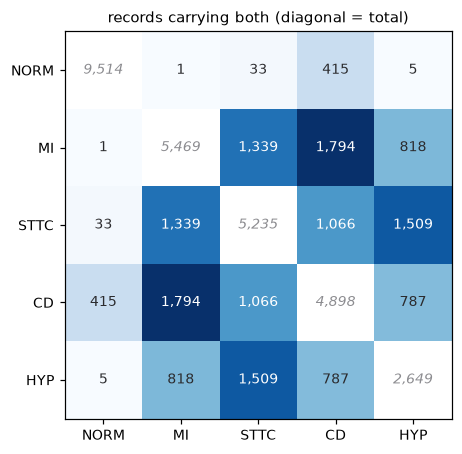

In [40]:
# co-occurrence: which findings travel together
ind = pd.DataFrame({c: db.supers.apply(lambda s: c in s) for c in SUPERCLASSES},
                   index=db.index)
co = ind.astype(int).T @ ind.astype(int)

fig, ax = plt.subplots(figsize=(5.2, 4.2))
m = co.values.astype(float).copy()
np.fill_diagonal(m, np.nan)
im = ax.imshow(m, cmap="Blues")
for i in range(5):
    for j in range(5):
        v = co.values[i, j]
        ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=9,
                color=("#8C8C90" if i == j else
                       ("white" if v > np.nanmax(m) * 0.55 else "#2B2B2E")),
                style="italic" if i == j else "normal")
ax.set_xticks(range(5)); ax.set_xticklabels(SUPERCLASSES)
ax.set_yticks(range(5)); ax.set_yticklabels(SUPERCLASSES)
ax.set_title("records carrying both (diagonal = total)", fontsize=10)
ax.grid(False)
plt.tight_layout(); plt.show()



**STTC with HYP** is common because hypertrophy produces the strain pattern: one
finding causes the other. **MI with CD** is common because infarcted tissue does
not conduct, so the damage and the conduction delay are the same event seen
twice.

**NORM with anything** should not happen, and it does. Which brings us to the
decisions we left for you.

---
## 4 Two decisions we left for you

These have no single right answer. Make a choice, apply it, and **write one
sentence for each in your Part 2 decision log.**

### Decision A: records that map to no superclass at all

In [41]:
none_at_all = db[db.n_super == 0]
print(f"records with zero superclasses: {len(none_at_all)}  "
      f"({100*len(none_at_all)/len(db):.2f}%)")
print("\ntheir raw codes are not empty, they just contain nothing diagnostic:")
for eid, row in none_at_all.head(4).iterrows():
    print(f"   {eid}: {row.scp_codes}")

records with zero superclasses: 411  (1.89%)

their raw codes are not empty, they just contain nothing diagnostic:
   17: {'AFLT': 100.0, 'ABQRS': 0.0, 'AFIB': 0.0}
   18: {'AFLT': 100.0}
   20: {'AFLT': 100.0, 'ABQRS': 0.0}
   23: {'AFLT': 100.0}


**Look at what those codes actually are before you decide.** `AFLT` is atrial
flutter. `AFIB` is atrial fibrillation. These are not empty records or annotation
failures. They are patients with a clinically important **rhythm** abnormality,
and the five superclasses only cover **diagnostic** statements. There is no slot
in this label space for "the rhythm is wrong".

So the decision is sharper than it first looks.

**Your options.** Drop them, accepting that you are removing atrial fibrillation
patients from your cohort and that your model will never have been shown one. Or
keep them as an **all-zero row**, a legitimate multi-label target meaning "none of
these five findings", which is genuinely different from NORM and which makes the
"all five sigmoids low" case learnable.

Either is defensible and most published work drops them. What is not defensible is
doing it without noticing. **If you drop them, say in one sentence which patients
left the study.**

### Decision B: records labelled NORM and something else

In [42]:
contradictory = db[(db.supers.apply(lambda s: "NORM" in s)) & (db.n_super >= 2)]
print(f"records labelled NORM AND another superclass: {len(contradictory)}")
print()
combos = contradictory.supers.apply(lambda s: " + ".join(s)).value_counts()
print(combos.head(8).to_string())

records labelled NORM AND another superclass: 445

supers
CD + NORM               407
NORM + STTC              28
CD + NORM + STTC          5
CD + HYP + NORM           2
HYP + NORM                2
CD + HYP + MI + NORM      1


**Your options.** Trust the annotation, on the grounds that some conduction
findings are considered normal variants and a cardiologist wrote it down. Or
treat NORM as exclusive and remove it from those records, on the grounds that a
recording cannot be both normal and abnormal.

Whichever you choose, notice what you are looking at: **a labelling
inconsistency in one of the most widely used ECG benchmarks in the world.** That
is not unusual, and finding it is part of the work.

### Apply your choices here

In [43]:
# --- EDIT THESE TWO LINES ---------------------------------------------------
DROP_UNLABELLED = True      # Decision A: True = drop, False = keep as all-zero
NORM_IS_EXCLUSIVE = True   # Decision B: True = strip NORM when others present
# ---------------------------------------------------------------------------

work = db.copy()

if NORM_IS_EXCLUSIVE:
    work["supers"] = work.supers.apply(
        lambda s: [c for c in s if c != "NORM"] if len(s) > 1 else s)
    work["n_super"] = work.supers.apply(len)

if DROP_UNLABELLED:
    work = work[work.n_super > 0]

Y = np.zeros((len(work), len(SUPERCLASSES)), dtype="float32")
for i, s in enumerate(work.supers):
    for c in s:
        Y[i, SUPERCLASSES.index(c)] = 1.0

print(f"records kept : {len(work):,} of {len(db):,}")
print(f"label matrix : {Y.shape}   (one row per record, one column per finding)")
print()
print("first five rows, which is exactly what your network will be trained on:")
print("        " + "  ".join(f"{c:>5}" for c in SUPERCLASSES))
for i in range(5):
    print(f"  {work.index[i]:>5} " + "  ".join(f"{int(v):>5}" for v in Y[i]))

records kept : 21,388 of 21,799
label matrix : (21388, 5)   (one row per record, one column per finding)

first five rows, which is exactly what your network will be trained on:
         NORM     MI   STTC     CD    HYP
      1     1      0      0      0      0
      2     1      0      0      0      0
      3     1      0      0      0      0
      4     1      0      0      0      0
      5     1      0      0      0      0


---
## 5 Loading the waveforms

This is the part that needs the 1.84 GB archive. **Use the 100 Hz records**
unless you can argue otherwise: a quarter of the size, roughly four times faster
to train, and the five superclasses do not depend on detail above 50 Hz.

One record is a `(1000, 12)` array: 10 seconds, 100 samples per second, 12 leads.
The whole set at 100 Hz is about **1.0 GB in float32**, so this cell is slow and
memory-hungry. Load once, then cache to disk.

In [44]:
def load_waveforms(frame, data_dir=DATA_DIR, sampling_rate=100):
    '''Return an (n, 1000, 12) float32 array in the order of `frame`.'''
    import wfdb
    col = "filename_lr" if sampling_rate == 100 else "filename_hr"
    out = []
    for i, path in enumerate(frame[col]):
        sig, _ = wfdb.rdsamp(os.path.join(data_dir, path))
        out.append(sig)
        if i % 2000 == 0:
            print(f"   {i:>6} / {len(frame)}", flush=True)
    return np.asarray(out, dtype="float32")


CACHE = "ptbxl_100hz.npy"

if os.path.exists(CACHE):
    X = np.load(CACHE)
    print("loaded from cache:", X.shape)
elif HAVE_LOCAL:
    print("reading waveforms, this takes a few minutes ...")
    X = load_waveforms(work)
    np.save(CACHE, X)
    print("cached to", CACHE, X.shape)
else:
    X = None
    print("SKIPPED - no local archive.")
    print("Download PTB-XL, set DATA_DIR at the top, and rerun this cell:")
    print("  https://physionet.org/content/ptb-xl/1.0.3/")

reading waveforms, this takes a few minutes ...
        0 / 21388
     2000 / 21388
     4000 / 21388
     6000 / 21388
     8000 / 21388
    10000 / 21388
    12000 / 21388
    14000 / 21388
    16000 / 21388
    18000 / 21388
    20000 / 21388
cached to ptbxl_100hz.npy (21388, 1000, 12)


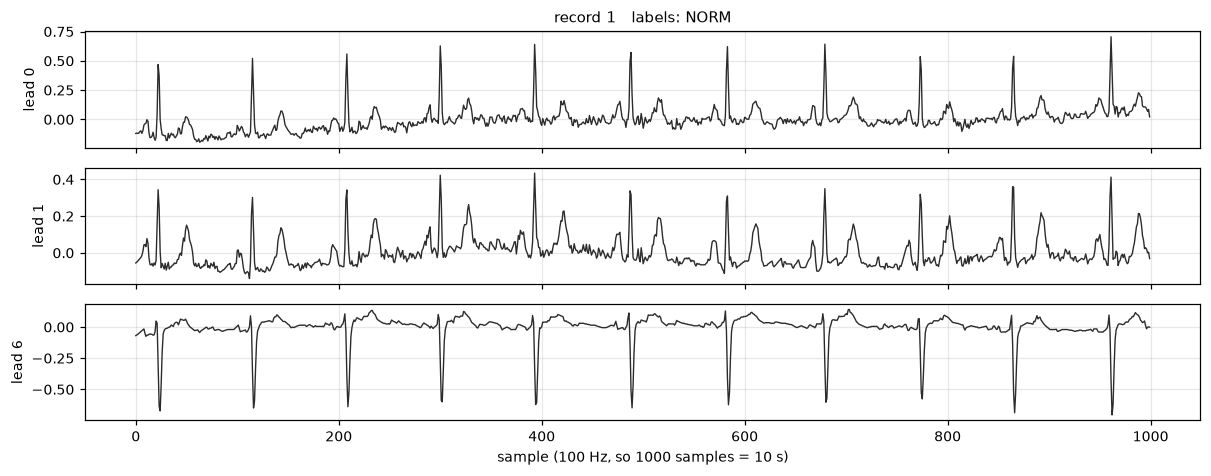

In [45]:
if X is not None:
    fig, axes = plt.subplots(3, 1, figsize=(11, 4.4), sharex=True)
    for ax, lead in zip(axes, [0, 1, 6]):
        ax.plot(X[0, :, lead], color="#2B2B2E", lw=0.9)
        ax.set_ylabel(f"lead {lead}")
    axes[-1].set_xlabel("sample (100 Hz, so 1000 samples = 10 s)")
    axes[0].set_title(f"record {work.index[0]}   labels: "
                      f"{', '.join(work.supers.iloc[0]) or 'none'}", fontsize=10)
    plt.tight_layout(); plt.show()
else:
    print("nothing to plot until the archive is downloaded")

---
## 6 The folds

PTB-XL ships with `strat_fold`, an integer 1 to 10. These folds are **grouped by
patient and stratified by diagnostic class**, and folds 9 and 10 were checked by
a human.

Use **1 to 8 for training, 9 for validation, 10 for testing**. Part 2 asks you to
say why these are better than a random split of your own. 

In [46]:
train = work[work.strat_fold <= 8]
val = work[work.strat_fold == 9]
test = work[work.strat_fold == 10]

idx = {k: work.index.get_indexer(v.index)
       for k, v in [("train", train), ("val", val), ("test", test)]}

print(f"{'':<8}{'records':>9}{'patients':>10}")
for k, v in [("train", train), ("val", val), ("test", test)]:
    print(f"{k:<8}{len(v):>9,}{v.patient_id.nunique():>10,}")
print()
overlap = (set(train.patient_id) & set(test.patient_id))
print("patients in BOTH train and test:", len(overlap))
print()
print("prevalence per split, which you need for Part 5:")
print(f"{'':<8}" + "".join(f"{c:>8}" for c in SUPERCLASSES))
for k in ["train", "val", "test"]:
    row = Y[idx[k]].mean(axis=0)
    print(f"{k:<8}" + "".join(f"{v:>8.3f}" for v in row))

          records  patients
train      17,084    14,823
val         2,146     1,917
test        2,158     1,877

patients in BOTH train and test: 0

prevalence per split, which you need for Part 5:
            NORM      MI    STTC      CD     HYP
train      0.424   0.256   0.245   0.229   0.124
val        0.426   0.252   0.246   0.231   0.125
test       0.423   0.255   0.241   0.230   0.121


---
## 7 Where you take over

You now have `X` (waveforms), `Y` (the five-column label matrix), and `idx`
(the fold indices). Everything from here is Parts 3 to 5.

**The only thing that makes this multi-label** is the last layer and the loss:

```python
# NOT softmax, and NOT categorical crossentropy
# multi-label
layers.Dense(5, activation="sigmoid")
loss = keras.losses.BinaryCrossentropy()

# multi-class
layers.Dense(5, activation="softmax")
loss = keras.losses.CategoricalCrossentropy()

```

Five independent yes/no questions, so nothing forces the outputs to sum to one.
A record can score high on MI and HYP at the same time, which is exactly what the example patient in the lecture needed.

**Evaluation.** `roc_auc_score` takes the multi-label matrix directly:

```python
macro = roc_auc_score(Y[idx["test"]], probs, average="macro")
per_class = roc_auc_score(Y[idx["test"]], probs, average=None)
```

Report **both**, with the class prevalence beside the per-class numbers. Part 5
marks the interpretation, not the average.

### What you still owe in Part 2

|||
|---|---|
| Decision A | drop or keep the unlabelled records, and why |
| Decision B | NORM exclusive or not, and why |
| Sampling rate | 100 Hz or 500 Hz, and why |
| Normalisation | per record or per dataset, and why |
| Folds | why the publisher's beat your own |



# Artificial Intelligence in Health Care - Exercise 3
## Diagnostic Classification from 12-Lead ECG

Mitglieder: Elbischger Selina, Krauss Marco  
Jahrgang: EHT25

Das Ziel der Übung ist es ein 1D-CNN mit einem recurrent network für die  Klassifikation von verschiedenen 12-Kanal-EKGs zu vergelichen.

Um Gleich vorweg die von uns geforderten und umgesetzten Entscheidungen zu rechtfertigen.  
1. Desicion A: Wir haben uns dazu entschieden, die 411 Aufzeichnungen auszuschließen, denen keine der fünf diagnostischen Superklassen zugeordnet war. Dadurch stehen uns weniger Aufzeichnungen für das Training zur Verfügung. Auch die Validierung und der Test beziehen sich damit nur auf EKGs mit mindestens einer annotierten Superklasse. Unter den ausgeschlossenen Aufzeichnungen sind zum Beispiel EKGs, bei denen nur ein Rhythmusbefund wie Vorhofflattern dokumentiert wurde. Unser Modell ist auf die fünf Superklassen ausgelegt. Aus unseren Ergebnissen lässt sich daher keine Aussage darüber ableiten, wie gut es Herzrhythmusstörungen erkennt.  

2. Desicion B: In der Datei scp_statements.csv steht NORM für „normal ECG“. Für unsere Umsetzung soll dieses Label nur dann vergeben werden, wenn dem EKG keine weitere diagnostische Superklasse zugeordnet ist. Deshalb haben wir beschlossen, bei Mehrfachannotierungen mit NORM dieses Label zu entfernen und die übrigen Labels beizubehalten. Ein EKG mit NORM und CD wird in unserer Auswertung somit nur der Klasse CD zugeordnet.

3. Aufgrund der eingeschränkten Rechenleistung des Laptops und der schnelleren Berechnungeszeiten werden wir den 100Hz Datensatz verwenden.

4. <p style="color: red;">NORMALIZIATION??</p>


5. Wir verwenden die vordefierten Folds, diese sind aus mehreren Gründen besser als selbst eingeteilte random folds:   
Erstens haben die Herausgeber alle EKGs einer Person demselben Fold zugeordnet. Bei einer zufälligen Aufteilung einzelner EKGs könnten Aufzeichnungen derselben Person im Training und im Test landen. Dadurch könnte die Testleistung optimistischer sein als bei bisher unbekannten Personen.  
Zweitens wurden die Folds stratifiziert, damit die Anteile der jeweiligen Diagnoseklassen über die Folds hinweg möglichst ähnlich sind. Das ist besonders bei seltenen Klassen wichtig, weil diese bei einer zufälligen Aufteilung im Trainingsset zu schwach vertreten sein könnten.  
Drittens wurden die Labels der Validierungs- und Testdaten zusätzlich von Menschen überprüft. Dadurch haben wir eine verlässlichere Grundlage für die Bewertung der Modelle.


### 1 Problem Formulation [1.5P]:
Before writing any modelling code, state in your own words:  

* **What is one sample? Be precise about its shape and what it represents.**
In diesem Beispiel ist ein Sample eine einzelne EKG-Aufzeichnung eines Patienten. Die Aufzeichnung dauert 10 Sekunden. Da wir die EKGs mit einer Abtastrate von 100 Hz verwenden, werden pro Sekunde 100 Messwerte je Ableitung erfasst. Bei 10 Sekunden sind das \(100 \times 10 = 1.000\) Messwerte für jede der 12 Ableitungen. Die Shape eines Samples ist demnach (1000, 12).   

* **What is the label? Derive the five diagnostic superclasses (NORM, MI, STTC, CD, HYP) from scp_codes. Explain why this is a multi-label problem and not multi-class, and what that changes about the output layer and the loss.**  
Die Labels leiten wir aus den diagnostischen Codes der EKG-Befunde ab, die in `ptbxl_database.csv` in der Spalte `scp_codes` stehen. Mithilfe von `scp_statements.csv` werden die Codes dann den fünf Superklassen NORM, MI, STTC, CD und HYP zugeordnet. Wenn einem EKG neben NORM noch eine weitere Superklasse zugeordnet ist, entfernen wir NORM und behalten die übrigen Labels.   
Bei einer Multiklassen-Klassifikation wird ein EKG genau einer Klasse zugeordnet. In unserer Aufgabe kann ein EKG aber gleichzeitig mehrere Superklassen aufweisen (z.B. MI und HYP). Deshalb handelt es sich um eine Multi-Label-Klassifikation. Der Output Layer hat fünf Neuronen mit jeweils einer Sigmoid-Funktion. So kann das Modell für jede Superklasse einen eigenen Wert ausgeben.   

* **Which sampling rate, and why. What information detail do we actually need?**  
Wir verwenden, wie bereits erwähnt, die 100Hz sampling rate. Für die Übung sind vor allem die Veränderungen des EKG-Signals im Laufe der Zeit relevant. Wir gehen davon aus, dass die für die Klassifikation wichtigen Veränderungen bei 100 Hz ausreichend gut erkennbar sind und wir die feinere zeitliche Auflösung von 500 Hz dafür nicht benötigen.  

* **What could not have been known at the time of prediction? From a model perspective. What does the model see vs. what does the cardiologist see?**  
Zum Zeitpunkt der Vorhersage stehen dem Modell lediglich die Messwerte des vollständigen 10‑Sekunden-EKGs zur Verfügung. Anhand der im Training gelernten Muster schätzt es ein, welche der fünf Superklassen auf das EKG zutreffen. Kardiologen können beim befunden zusätzlich bereits vorliegende Informationen zu Vorerkrankungen, Symptomen oder Medikamenten berücksichtigen. Außerdem könnten sie das aktuelle EKG mit früheren EKGs vergleichen.  


### 2 Folds and Preprocessing [2P]:
* **Use the publisher’s stratified folds: train on 1–8, validate on 9, test on 10. Justify why these are preferable to a fresh random split of your own. One sentence on patients, one on stratification.**  
Hamma bereits bei Punkt 5 weiter oben erklärt :)  

* **Report the class prevalence of each superclass in your training set. You will need it to interpret Part 5.**  
Die Prävalenz der Superklassen pro Testset wurde netterweise bereits im Starter berechnet:

    | Datensatz | NORM | MI | STTC | CD | HYP |
    |---|---:|---:|---:|---:|---:|
    | Training | 42,4 % | 25,6 % | 24,5 % | 22,9 % | 12,4 % |
    | Validierung | 42,6 % | 25,2 % | 24,6 % | 23,1 % | 12,5 % |
    | Test | 42,3 % | 25,5 % | 24,1 % | 23,0 % | 12,1 % |  

* **Keep a preprocessing decision log:**  
    1. Ad sampling rate: siehe task 1 Punkt 3    
    2. Ad window handling: Ein Window entspricht einem Sample -> wie dieses definiert ist, siehe in Task 1 Punkt 1. 
    3. Ad how you deal with records carrying no superclass: siehe Beginn der Übung Punkt 1 - wir schließen diese records aus.  
    4. Ad **normalisation** (and whether it is per-record or per-dataset, and why)  
    Für die Umsetzung der Übung verwenden wir eine Per-Dataset-Normalisierung. Dabei berechnen wir Mittelwert und Standardabweichung aus den Trainingsdaten und verwenden dieselben Werte auch für die Validierungs- und Testdaten. So bleiben Unterschiede in der Stärke der Ausschläge zwischen den EKGs erhalten und können vom Modell für die Klassifikation genutzt werden.  
    Wir können entweder alle zwölf Ableitungen gemeinsam oder jede Ableitung separat normalisieren. Bei der separaten Normalisierung bekommt jede Ableitung ihre eigene Skala, die für alle EKGs gleich ist. Dadurch können auch feine Veränderungen in Ableitungen mit typischerweise kleinen Ausschlägen beim Training stärker ins Gewicht fallen.

    <p style="color: red;">Normalisierung per dataset ja aber das ganze normalisieren oder übern gesamten datensatz jede ableitung normalisieren? weil wsl ist für lernen und auswertung ja eher der untershcied zwischen den ableitungen wichtiger oder??</p>

In [47]:
# per-dataset normalisierung
# Zuteilung der Folds zu train, val, test
X_train = X[idx["train"]]
X_val = X[idx["val"]]    
X_test = X[idx["test"]]

#Mittelwert und Standardabweichung pro Ableitung
mean = X_train.mean(axis=(0, 1), dtype="float64")           #weil ich zu doof bin: axis=(0, 1) heißt: Mittle über die EKGs (0) und über die Zeitpunkte (1)
std = X_train.std(axis=(0, 1), dtype="float64")

#Mittewert und Standardabweichung gesamter Datensatz
#mean = X_train.mean(axis=(0, 1, 2), dtype="float64")       #axis kann auch entfernt werden dann automaisch über alle Achsen mitteln
#std = X_train.std(axis=(0, 1, 2), dtype="float64")

# Normalisierung der Datensätze
X_train = (X_train - mean) / std
X_val = (X_val - mean) / std
X_test = (X_test - mean) / std